In [1]:
import pandas as pd

# membaca dataset dan mengubahnya menjadi dataframe
data = pd.read_csv('Salary_Data.csv')

In [2]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes


In [3]:
data.head()

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


In [4]:
import numpy as np

# memisahkan atribut dan label
X = data['YearsExperience']
y = data['Salary']

# mengubah bentuk atribut
X = np.array(X)
X = X[:,np.newaxis]

In [8]:
from sklearn.svm import SVR

# membangun model dengan parameter C, gamma, dan kernel
model = SVR(C=1000, gamma=0.05, kernel='rbf')

# melatih model dengan fungsi fit
model.fit(X,y)

,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",0.05
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1000
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


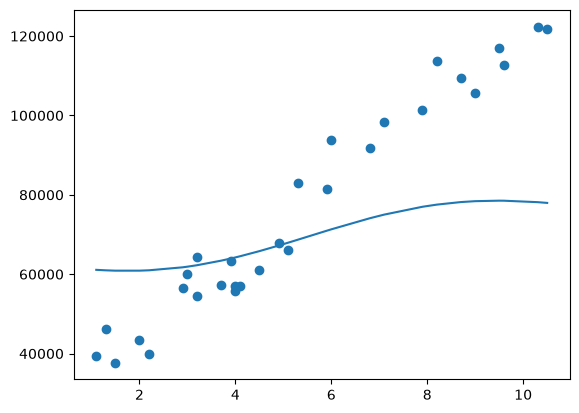

In [9]:
import matplotlib.pyplot as plt

# memvisualisasikan model
plt.scatter(X, y)
plt.plot(X, model.predict(X))

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Sesuaikan path jika file berada di folder lain
df = pd.read_csv("Salary_Data.csv")

# Menampilkan beberapa baris pertama
display(df.head())

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


In [11]:
print("Ukuran dataset (baris, kolom):", df.shape)
print("\\nInformasi dataset:")
df.info()

print("\\nJumlah data kosong:")
display(df.isnull().sum())

print("\\nJumlah data duplikat:", df.duplicated().sum())

print("\\nStatistik deskriptif:")
display(df.describe())

Ukuran dataset (baris, kolom): (30, 2)
\nInformasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes
\nJumlah data kosong:


YearsExperience    0
Salary             0
dtype: int64

\nJumlah data duplikat: 0
\nStatistik deskriptif:


,YearsExperience,Salary
count,30.000000,30.000000
mean,5.313333,76003.000000
std,2.837888,27414.429785
min,1.100000,37731.000000
25%,3.200000,56720.750000
50%,4.700000,65237.000000
75%,7.700000,100544.750000
max,10.500000,122391.000000


In [12]:
identifikasi = pd.DataFrame({
    "Atribut": df.columns,
    "Tipe Data": [df[col].dtype for col in df.columns],
    "Jumlah Nilai Unik": [df[col].nunique() for col in df.columns],
    "Jenis Atribut": ["Numerik kontinu" if pd.api.types.is_numeric_dtype(df[col]) else "Kategorikal"
                      for col in df.columns],
    "Keterangan": [
        "Lama pengalaman kerja dalam tahun",
        "Besaran gaji; satuan tidak dicantumkan dalam file"
    ]
})

display(identifikasi)

,Atribut,Tipe Data,Jumlah Nilai Unik,Jenis Atribut,Keterangan
0,YearsExperience,float64,28,Numerik kontinu,Lama pengalaman kerja dalam tahun
1,Salary,float64,30,Numerik kontinu,Besaran gaji; satuan tidak dicantumkan dalam file


In [13]:
# Membagi YearsExperience menjadi tiga kelompok berdasarkan kuantil
df["KategoriPengalaman"] = pd.qcut(
    df["YearsExperience"],
    q=3,
    labels=["Rendah", "Sedang", "Tinggi"],
    duplicates="drop"
)

# Membagi Salary menjadi tiga kelompok berdasarkan kuantil
df["KategoriGaji"] = pd.qcut(
    df["Salary"],
    q=3,
    labels=["Rendah", "Sedang", "Tinggi"],
    duplicates="drop"
)

print("Batas kategori pengalaman kerja:")
print(pd.qcut(df["YearsExperience"], q=3, duplicates="drop").value_counts().sort_index())

print("\\nBatas kategori gaji:")
print(pd.qcut(df["Salary"], q=3, duplicates="drop").value_counts().sort_index())

display(df.head(10))

Batas kategori pengalaman kerja:
YearsExperience
(1.0990000000000002, 3.833]    10
(3.833, 6.267]                 10
(6.267, 10.5]                  10
Name: count, dtype: int64
\nBatas kategori gaji:
Salary
(37730.999, 57153.0]    10
(57153.0, 92472.0]      10
(92472.0, 122391.0]     10
Name: count, dtype: int64


,YearsExperience,Salary,KategoriPengalaman,KategoriGaji
0,1.1,39343.0,Rendah,Rendah
1,1.3,46205.0,Rendah,Rendah
2,1.5,37731.0,Rendah,Rendah
3,2.0,43525.0,Rendah,Rendah
4,2.2,39891.0,Rendah,Rendah
5,2.9,56642.0,Rendah,Rendah
6,3.0,60150.0,Rendah,Sedang
7,3.2,54445.0,Rendah,Rendah
8,3.2,64445.0,Rendah,Sedang
9,3.7,57189.0,Rendah,Sedang


In [14]:
print("Distribusi kategori pengalaman kerja:")
display(df["KategoriPengalaman"].value_counts().reindex(["Rendah", "Sedang", "Tinggi"]))

print("Distribusi kategori gaji:")
display(df["KategoriGaji"].value_counts().reindex(["Rendah", "Sedang", "Tinggi"]))

print("Tabulasi silang kategori pengalaman dan gaji:")
display(pd.crosstab(df["KategoriPengalaman"], df["KategoriGaji"]))

Distribusi kategori pengalaman kerja:


KategoriPengalaman
Rendah    10
Sedang    10
Tinggi    10
Name: count, dtype: int64

Distribusi kategori gaji:


KategoriGaji
Rendah    10
Sedang    10
Tinggi    10
Name: count, dtype: int64

Tabulasi silang kategori pengalaman dan gaji:


KategoriGaji,Rendah,Sedang,Tinggi
KategoriPengalaman,,,
Rendah,7,3,0
Sedang,3,6,1
Tinggi,0,1,9


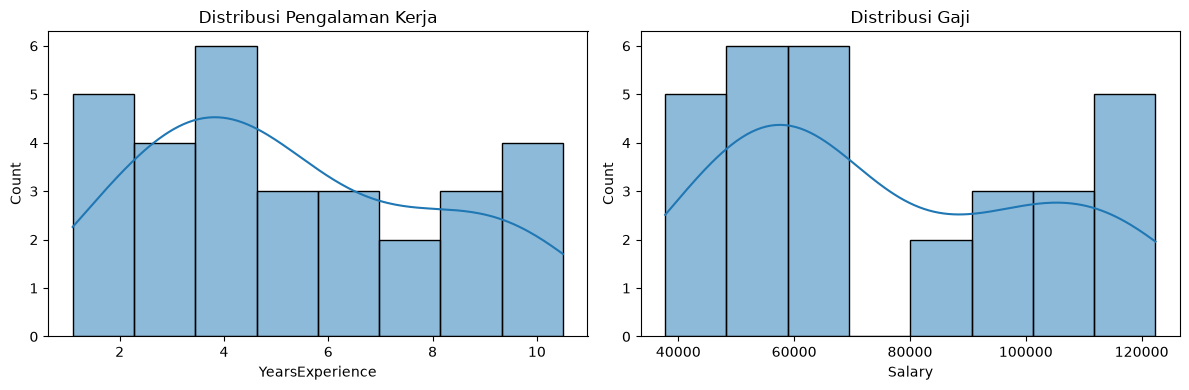

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=df, x="YearsExperience", bins=8, kde=True, ax=axes[0])
axes[0].set_title("Distribusi Pengalaman Kerja")
axes[0].set_xlabel("YearsExperience")

sns.histplot(data=df, x="Salary", bins=8, kde=True, ax=axes[1])
axes[1].set_title("Distribusi Gaji")
axes[1].set_xlabel("Salary")

plt.tight_layout()
plt.show()